<center>
<img src="../images/fscampus_small2.png" width="1200"/>
</center>

<center>

# Investments

***Finance 2 - BFIN***

**Dr. Omer Cayirli**

Lecturer in Empirical Finance

omer_cayirli@uncbusiness.net
</center>

---

## Lecture 10

---


### Outline

*   Derivatives II
    *   Option positions and strategies
    *   Replication and put-call parity
    *   Price determinants
    *   Early exercise
    *   Equity and risky debt
    *   Price bounds

---



### Introduction to Options

*   Contingent Claims
    *   Their payoffs depend on an uncertain outcome.
    *   An option gives its holder the right, but not the obligation, to buy or sell an underlying asset at the strike price $K$.

| Contract | Holder (Long) | Writer (Short) |
| :--- | :--- | :--- |
| Call | Right to buy at $K$ | Obligation to sell if exercised |
| Put | Right to sell at $K$ | Obligation to buy if exercised |

*   The holder pays the writer a premium for this right.

*   Exercise Style
    *   A European option can be exercised only at expiration $T$.
    *   An American option can be exercised at any time up to and including $T$.

---



### Moneyness and Intrinsic Value

Let $S$ be the current stock price.

| Status | Call | Put |
| :--- | :--- | :--- |
| In the money | $S>K$ | $S<K$ |
| At the money | $S=K$ | $S=K$ |
| Out of the money | $S<K$ | $S>K$ |
| Intrinsic value | $\max(S-K,0)$ | $\max(K-S,0)$ |

*   Intrinsic Value
    *   The value from exercising the option at the current stock price, or zero if exercise is unfavorable.
    *   Moneyness compares the stock price with the strike; it does not account for the premium paid.

*   Time Value
    *   The difference between the option price and its intrinsic value.
    $$\text{Time value}=\text{Option price}-\text{Intrinsic value}.$$

---



### Option Payoffs and Profit

$S_T$: Stock price at expiration; $C$ and $P$: Initial call and put premiums.

| Position | Payoff at $T$ | Profit |
| :--- | :--- | :--- |
| Long call | $\max(S_T-K,0)$ | $\max(S_T-K,0)-C$ |
| Short call | $-\max(S_T-K,0)$ | $C-\max(S_T-K,0)$ |
| Long put | $\max(K-S_T,0)$ | $\max(K-S_T,0)-P$ |
| Short put | $-\max(K-S_T,0)$ | $P-\max(K-S_T,0)$ |

*   Breakeven Stock Price
    *   A long call breaks even at $S_T=K+C$.
    *   A long put breaks even at $S_T=K-P$, provided this is nonnegative.

---



In [7]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def plot_option_positions(call_premium=8, put_premium=6):
    K = 100
    stock = np.linspace(0, 200, 401)
    call = np.maximum(stock - K, 0)
    put = np.maximum(K - stock, 0)
    positions = [
        ("Long Call", call, call - call_premium),
        ("Short Call", -call, call_premium - call),
        ("Long Put", put, put - put_premium),
        ("Short Put", -put, put_premium - put),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
    for ax, (title, payoff, profit) in zip(axes.flat, positions):
        ax.plot(stock, payoff, "--", color="#666666", lw=2, label="Payoff")
        ax.plot(stock, profit, color="#005A9C", lw=2.5, label="Profit")
        ax.axhline(0, color="black", lw=0.8)
        ax.axvline(K, color="#999999", ls=":", lw=1)
        ax.set(title=title, xlim=(0, 200), ylim=(-115, 115))
        ax.grid(alpha=0.2)
    for ax in axes[-1]:
        ax.set_xlabel("Stock Price at Expiration ($)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Payoff / Profit ($)")
    axes[0, 0].legend(loc="upper left")
    fig.suptitle("Strike $100 | Profit Includes Premium; Financing Costs Ignored")
    fig.tight_layout()
    plt.show()

position_controls = {
    "call_premium": widgets.FloatSlider(value=8, min=0, max=15, step=0.5,
        description="Call premium", continuous_update=False),
    "put_premium": widgets.FloatSlider(value=6, min=0, max=15, step=0.5,
        description="Put premium", continuous_update=False),
}
display(widgets.VBox([
    widgets.HBox(list(position_controls.values())),
    widgets.interactive_output(plot_option_positions, position_controls),
]))


### Option Strategies: Protection and Covered Calls

| Position | $S_T\le K$ | $S_T>K$ |
| :--- | :--- | :--- |
| Stock | $S_T$ | $S_T$ |
| Long put | $K-S_T$ | $0$ |
| Protective put: Stock + Put | $K$ | $S_T$ |
| Short call | $0$ | $-(S_T-K)$ |
| Covered call: Stock $-$ Call | $S_T$ | $K$ |

*   Protective Put
    *   Buying the put sets a floor of $K$ on the portfolio's terminal value while retaining the stock's upside.
    *   The protection costs the put premium.

*   Covered Call
    *   Writing the call generates premium income but gives up stock gains above $K$.
    *   The investor still bears substantial losses if the stock price falls.

*   Portfolio profit equals terminal value minus the initial net cost.

---



In [8]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def plot_stock_hedges(premium=6):
    S0 = K = 100
    stock = np.linspace(0, 200, 401)
    stock_profit = stock - S0
    put_profit = np.maximum(K - stock, 0) - premium
    short_call_profit = premium - np.maximum(stock - K, 0)
    panels = [
        ("Protective Put", put_profit, stock_profit + put_profit, "Long Put"),
        ("Covered Call", short_call_profit, stock_profit + short_call_profit, "Short Call"),
    ]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
    for ax, (title, option_profit, total, label) in zip(axes, panels):
        ax.plot(stock, stock_profit, "--", color="#666666", label="Stock")
        ax.plot(stock, option_profit, ":", color="#B24C00", lw=2, label=label)
        ax.plot(stock, total, color="#005A9C", lw=2.8, label="Combined")
        ax.axhline(0, color="black", lw=0.8)
        ax.axvline(K, color="#999999", ls=":")
        ax.set(title=title, xlim=(0, 200), ylim=(-120, 125),
               xlabel="Stock Price at Expiration ($)")
        ax.grid(alpha=0.2)
        ax.legend(loc="upper left")
    axes[0].set_ylabel("Profit ($)")
    fig.suptitle("Stock Cost and Strike $100 | Financing Costs Ignored")
    fig.tight_layout()
    plt.show()

hedge_controls = {
    "premium": widgets.FloatSlider(value=6, min=0, max=15, step=0.5,
        description="Premium", continuous_update=False),
}
display(widgets.VBox([
    widgets.HBox(list(hedge_controls.values())),
    widgets.interactive_output(plot_stock_hedges, hedge_controls),
]))


### Option Strategies: Bull and Bear Spreads

Both options have the same expiration, with strikes $K_L<K_H$.

*   Bull Call Spread
    *   Buy a call at $K_L$ and sell a call at $K_H$.

*   Bear Put Spread
    *   Buy a put at $K_H$ and sell a put at $K_L$.

| Terminal payoff | $S_T\le K_L$ | $K_L<S_T<K_H$ | $S_T\ge K_H$ |
| :--- | :--- | :--- | :--- |
| Bull call | $0$ | $S_T-K_L$ | $K_H-K_L$ |
| Bear put | $K_H-K_L$ | $K_H-S_T$ | $0$ |

*   Risk and Return
    *   For a net premium $d$, the maximum loss is $d$ and the maximum profit is $K_H-K_L-d$.
    *   The bull spread breaks even at $K_L+d$; the bear spread at $K_H-d$.
    *   Selling the second option reduces the initial cost and limits the potential gain.

---



In [9]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def spread_payoff(stock, strategy):
    low, high = 90, 110
    if strategy == "Bull Call":
        return np.maximum(stock - low, 0) - np.maximum(stock - high, 0)
    if strategy == "Bear Put":
        return np.maximum(high - stock, 0) - np.maximum(low - stock, 0)
    raise ValueError("Choose Bull Call or Bear Put.")

def plot_vertical_spread(strategy="Bull Call", cost=8):
    stock = np.linspace(60, 140, 401)
    payoff = spread_payoff(stock, strategy)
    profit = payoff - cost
    breakeven = 90 + cost if strategy == "Bull Call" else 110 - cost
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.plot(stock, payoff, "--", color="#666666", lw=2, label="Payoff")
    ax.plot(stock, profit, color="#005A9C", lw=2.8, label="Profit")
    for strike in (90, 110):
        ax.axvline(strike, color="#999999", ls=":", lw=1)
    ax.scatter([breakeven], [0], color="#B24C00", zorder=3,
               label=f"Breakeven USD {breakeven:.2f}")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=f"{strategy}: Strikes USD 90 and USD 110 | Net Premium USD {cost:.2f}",
           xlabel="Stock Price at Expiration ($)", ylabel="Payoff / Profit ($)",
           xlim=(60, 140), ylim=(-22, 22))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
    fig.tight_layout()
    plt.show()
    print(f"Maximum loss: USD {cost:.2f} | Maximum profit: USD {20-cost:.2f}")

spread_controls = {
    "strategy": widgets.Dropdown(options=["Bull Call", "Bear Put"], description="Strategy"),
    "cost": widgets.FloatSlider(value=8, min=0, max=20, step=0.5,
        description="Net premium", continuous_update=False),
}
display(widgets.VBox([
    widgets.HBox(list(spread_controls.values())),
    widgets.interactive_output(plot_vertical_spread, spread_controls),
]))


### Option Strategies: Large and Small Price Moves

*   Positions for Large Price Moves
    *   Long straddle: Buy a put and a call at the same strike.
    *   Long strangle: Buy a put at $K_L$ and a call at $K_H$, where $K_L<K_H$.

| Strangle payoff | $S_T\le K_L$ | $K_L<S_T<K_H$ | $S_T\ge K_H$ |
| :--- | :--- | :--- | :--- |
| Put + Call | $K_L-S_T$ | $0$ | $S_T-K_H$ |

*   The stock price must move far enough to recover the total premium $d$.
    *   The maximum loss is $d$.
    *   The strangle breaks even at $K_L-d$ (if nonnegative) and $K_H+d$.

*   Position for Small Price Moves
    *   A long call butterfly buys calls at $K_L$ and $K_H$ and sells two calls at $K_M=(K_L+K_H)/2$.

| Butterfly payoff | $S_T\le K_L$ | $K_L<S_T\le K_M$ | $K_M<S_T<K_H$ | $S_T\ge K_H$ |
| :--- | :--- | :--- | :--- | :--- |
| $C_L-2C_M+C_H$ at expiry | $0$ | $S_T-K_L$ | $K_H-S_T$ | $0$ |

*   The butterfly has its highest payoff at $K_M$; its maximum loss is the net premium paid.

---



In [10]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def movement_payoff(stock, strategy):
    if strategy == "Straddle":
        return np.maximum(stock - 100, 0) + np.maximum(100 - stock, 0)
    if strategy == "Strangle":
        return np.maximum(stock - 110, 0) + np.maximum(90 - stock, 0)
    if strategy == "Butterfly":
        return (np.maximum(stock - 90, 0) - 2*np.maximum(stock - 100, 0)
                + np.maximum(stock - 110, 0))
    raise ValueError("Choose Straddle, Strangle or Butterfly.")

def plot_price_movement(strategy="Straddle", cost=4):
    stock = np.linspace(60, 140, 401)
    payoff = movement_payoff(stock, strategy)
    strikes = {"Straddle": [100], "Strangle": [90, 110], "Butterfly": [90, 100, 110]}
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.plot(stock, payoff, "--", color="#666666", lw=2, label="Payoff")
    ax.plot(stock, payoff-cost, color="#005A9C", lw=2.8, label="Profit")
    for strike in strikes[strategy]:
        ax.axvline(strike, color="#999999", ls=":", lw=1)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=f"Long {strategy} | Net Premium USD {cost:.2f}",
           xlabel="Stock Price at Expiration ($)", ylabel="Payoff / Profit ($)",
           xlim=(60, 140), ylim=(-12, 42))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper center")
    fig.tight_layout()
    plt.show()

movement_controls = {
    "strategy": widgets.Dropdown(options=["Straddle", "Strangle", "Butterfly"],
        description="Strategy"),
    "cost": widgets.FloatSlider(value=4, min=0, max=10, step=0.5,
        description="Net premium", continuous_update=False),
}
display(widgets.VBox([
    widgets.HBox(list(movement_controls.values())),
    widgets.interactive_output(plot_price_movement, movement_controls),
]))


### Put-Call Parity: Replicating Portfolio Insurance

Consider European options with the same strike $K$ and expiration $T$, on a stock paying no dividends before expiration.

| Portfolio | Cost today | $S_T\le K$ | $S_T>K$ |
| :--- | :--- | :--- | :--- |
| Protective put: Stock + Put | $S_0+P$ | $S_T+(K-S_T)=K$ | $S_T$ |
| Fiduciary call: Bond + Call | $PV(K)+C$ | $K$ | $K+(S_T-K)=S_T$ |

*   Both portfolios pay $\max(S_T,K)$ at expiration, regardless of the stock price.
    *   By the law of one price, they must have the same cost today.

$$S_0+P=PV(K)+C$$

*   The floor protects terminal value; it need not cover the initial portfolio cost.

---



### Put-Call Parity: Synthetic Positions

Assume European options on the same stock, with the same strike and expiration, and no dividends. Borrowing, lending and short selling are frictionless.

$$C-P=S_0-PV(K)$$

| Position | Replication |
| :--- | :--- |
| Call | Stock + Put $-$ Bond |
| Put | Call + Bond $-$ Stock |

*   Discounting the Strike
    *   With an annual effective rate, $PV(K)=K/(1+r_f)^T$.
    *   With a continuously compounded rate, $PV(K)=Ke^{-rT}$.

*   If an option and its replication have different market prices, buy the cheaper position and sell the more expensive one.

*   With known cash dividends before expiration, subtract their present value:

$$C-P=S_0-PV(D)-PV(K)$$

---



### Put-Call Parity: Beta

*   Beta stock trades at $\$45$ and pays no dividends.
    *   A European call with a strike of $\$60$ expires in four months and costs $\$2$.
    *   The risk-free rate is 3% per year, continuously compounded.

What is the price of the matching European put?

$$P=C+Ke^{-rT}-S_0$$
$$P=2+60e^{-0.03(4/12)}-45=\$16.40$$

---



### Put-Call Parity: Alpha

*   European call and put options on Alpha expire in six months.
    *   Both have a strike of $\$80$ and trade at $\$12$.
    *   The stock pays no dividends, and the annual effective risk-free rate is 4%.

What stock price is consistent with these quotes?

$$C-P=S_0-PV(K)=0$$
$$S_0=PV(K)=\frac{80}{1.04^{0.5}}=\$78.45$$

---



### Factors Affecting Option Prices

For European options, consider a change in one input while holding the others fixed.

| Increase in | Call value | Put value |
| :--- | :---: | :---: |
| Stock price $S_0$ | Increases | Decreases |
| Strike $K$ | Decreases | Increases |
| Volatility $\sigma$ | Increases | Increases |
| Risk-free rate $r$ | Increases | Decreases |
| Expected dividends | Decreases | Increases |
| Time to expiration $T$ | Depends | Depends |

*   Economic Intuition
    *   Higher volatility increases the potential gain while the exercise payoff remains floored at zero.
    *   Dividends reduce the stock value available to option holders.
    *   Interest rates affect the present value of the strike.

---



### Factors Affecting Option Prices: Time to Expiration

*   American Options
    *   More time cannot reduce value.
    *   The longer-lived option includes every exercise opportunity of the shorter-lived option.

*   European Options
    *   Different expiration dates mean different exercise opportunities.
    *   With no dividends and $r\ge0$, a longer-lived call cannot be worth less.
    *   Puts can lose value as receiving the strike is delayed.
    *   Dividends can also make a longer-lived call less valuable.

*   More time and more volatility are different effects.

---



In [11]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from functools import lru_cache
from scipy.stats import norm, binom
from IPython.display import display

def european_prices(stock, strike, years, rate, volatility):
    stock = np.asarray(stock, dtype=float)
    if (np.any(~np.isfinite(stock)) or np.any(stock <= 0)
            or not np.all(np.isfinite([strike, years, rate, volatility]))
            or strike <= 0 or years < 0 or volatility < 0):
        raise ValueError("Finite inputs; positive stock and strike; nonnegative time and volatility required.")
    pv_strike = strike * np.exp(-rate * years)
    if years == 0 or volatility == 0:
        return np.maximum(stock-pv_strike, 0), np.maximum(pv_strike-stock, 0)
    d1 = (np.log(stock/strike)+(rate+0.5*volatility**2)*years)/(volatility*np.sqrt(years))
    d2 = d1-volatility*np.sqrt(years)
    call = stock*norm.cdf(d1)-pv_strike*norm.cdf(d2)
    put = pv_strike*norm.cdf(-d2)-stock*norm.cdf(-d1)
    return call, put

def american_prices(stock, strike, years, rate, volatility, steps=400):
    """No dividends, nonnegative rates; CRR put with a European control variate."""
    call, european_put = european_prices(stock, strike, years, rate, volatility)
    if rate < 0:
        raise ValueError("This American-option illustration assumes nonnegative rates.")
    if not isinstance(steps, (int, np.integer)) or steps < 1:
        raise ValueError("steps must be a positive integer.")
    stock = np.asarray(stock, dtype=float)
    intrinsic_put = np.maximum(strike-stock, 0)
    # A no-dividend American call equals its European counterpart.
    if years == 0 or rate == 0:
        return call, european_put
    if volatility == 0:
        return call, intrinsic_put

    dt = years/steps
    log_up = volatility*np.sqrt(dt)
    up, down = np.exp(log_up), np.exp(-log_up)
    probability = (np.exp(rate*dt)-down)/(up-down)
    if not 0 <= probability <= 1:
        raise ValueError("Increase the tree steps to obtain valid risk-neutral probabilities.")
    discount = np.exp(-rate*dt)
    j = np.arange(steps+1)
    terminal_stock = stock[..., None]*np.exp((2*j-steps)*log_up)
    values = np.maximum(strike-terminal_stock, 0)
    european_tree_put = np.exp(-rate*years)*np.sum(
        values*binom.pmf(j, steps, probability), axis=-1
    )

    for level in range(steps-1, -1, -1):
        continuation = discount*((1-probability)*values[..., :-1]
                                 + probability*values[..., 1:])
        node_stock = stock[..., None]*np.exp((2*np.arange(level+1)-level)*log_up)
        values = np.maximum(continuation, strike-node_stock)

    # Add the tree's early-exercise premium to the exact European price.
    # The small control-variate correction must also respect immediate exercise.
    exercise_premium = np.maximum(values[..., 0]-european_tree_put, 0)
    american_put = np.maximum(intrinsic_put, european_put+exercise_premium)
    return call, american_put

sensitivity_stock = np.linspace(60, 140, 401)

@lru_cache(maxsize=16)
def sensitivity_prices(years, rate, volatility):
    european = european_prices(sensitivity_stock, 100, years, rate, volatility)
    american = american_prices(sensitivity_stock, 100, years, rate, volatility)
    return european, american

def plot_price_sensitivity(volatility_pct=30, years=1, rate_pct=4):
    baseline = sensitivity_prices(1, 0.04, 0.20)
    selected = sensitivity_prices(years, rate_pct/100, volatility_pct/100)
    payoffs = (np.maximum(sensitivity_stock-100, 0),
               np.maximum(100-sensitivity_stock, 0))
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True,
                             layout="constrained")
    for row, style in enumerate(["European", "American"]):
        for col, kind in enumerate(["Call", "Put"]):
            ax = axes[row, col]
            ax.plot(sensitivity_stock, baseline[row][col], "--",
                    color="#666666", lw=2, label="Baseline Value")
            ax.plot(sensitivity_stock, selected[row][col],
                    color="#005A9C", lw=2.5, label="Selected Value")
            ax.plot(sensitivity_stock, payoffs[col], "-.",
                    color="#D55E00", lw=2, label="Exercise Payoff")
            ax.axvline(100, color="#999999", ls=":", lw=1)
            ax.set(title=f"{style} {kind}", xlim=(60, 140), ylim=(0, 75))
            ax.grid(alpha=0.2)
            ax.legend(loc="upper left", fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel("Stock Price ($)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Option Value / Payoff ($)")
    fig.suptitle("Option Values and Exercise Payoffs: Strike $100; No Dividends")
    plt.show()
    print("Baseline: volatility 20%, maturity 1 year, continuously compounded rate 4%.")
    print("Payoff lines show intrinsic value at each stock price; European exercise is only at expiry.")
    print("No dividends: American and European calls coincide; American puts allow early exercise.")
    print("Illustrative prices: Black-Scholes and a 400-step binomial model (Lecture 11).")

sensitivity_controls = {
    "volatility_pct": widgets.IntSlider(value=30, min=5, max=60, step=5,
        description="Volatility %", continuous_update=False),
    "years": widgets.FloatSlider(value=1, min=0.25, max=2, step=0.25,
        description="Years", continuous_update=False),
    "rate_pct": widgets.IntSlider(value=4, min=0, max=10, step=1,
        description="Rate %", continuous_update=False),
}
display(widgets.VBox([
    widgets.HBox(list(sensitivity_controls.values())),
    widgets.interactive_output(plot_price_sensitivity, sensitivity_controls),
]))


### Early Exercise: No Dividends

Assume $r\ge0$. Let $dis(K)=K-PV(K)$ denote the interest benefit from delaying payment of the strike.

*   American Calls
    *   Early exercise offers no advantage.
    *   Retain the downside protection and delay paying $K$.
    *   From European parity:

$$C_{\mathrm{eur}}-(S_0-K)=P_{\mathrm{eur}}+dis(K)\ge0$$

*   American Puts
    *   Early exercise can be optimal.
    *   Receive $K$ sooner; give up protection against a stock-price recovery.
    *   For an in-the-money European put:

$$P_{\mathrm{eur}}-(K-S_0)=C_{\mathrm{eur}}-dis(K)$$

*   European time value can be negative; American time value cannot.

*   Exercise an American option when intrinsic value is at least its continuation value.

---



### Early Exercise: Dividends

*   American Calls
    *   Exercise may be optimal just before an ex-dividend date because the shareholder receives the dividend.
    *   Exercising also means paying the strike sooner and giving up the remaining option protection.

*   Suppose one dividend $D$ remains at $t_d$, before expiration $T$, and $r\ge0$.
    *   For early exercise to be strictly preferable, the dividend must exceed the interest forgone from $t_d$ to $T$:

$$D>K\left(1-e^{-r(T-t_d)}\right)$$

*   This condition is necessary but not sufficient; the remaining option value also matters.

*   American Puts
    *   The expected stock-price drop makes waiting more attractive.

---



### Early Exercise: Delta

*   Delta stock trades at $\$120$ just before paying a cash dividend of $\$0.40$.
    *   An American call has a strike of $\$100$ and expires one month after the ex-dividend date.
    *   The risk-free rate is 3% APR, compounded monthly, and no further dividends are due.
    *   The matching European put immediately after the ex-dividend date is worth $\$0.05$.

Should the call holder exercise?

*   Compare Exercise with Continuation
    *   Immediate exercise is worth $120-100=\$20$.
    *   After the dividend, the stock price is $120-0.40=\$119.60$.
    *   With no further dividends, $C_{\mathrm{amer}}=C_{\mathrm{eur}}$. Parity gives the continuation value:

$$C_{\mathrm{continue}}=119.60+0.05-\frac{100}{1.0025}=\$19.8994$$

*   The exercise advantage equals the dividend minus the interest forgone and the put value:

$$0.40-\left(100-\frac{100}{1.0025}\right)-0.05=\$0.1006$$

*   Exercise just before the ex-dividend date, since $\$20>\$19.8994$.

---



### Options and Corporate Finance

Consider a firm with assets worth $V_T$ and one zero-coupon debt payment $K$ due at $T$. Assume limited liability, no bankruptcy costs and no earlier payouts.

| Claim | $V_T<K$ | $V_T\ge K$ |
| :--- | :--- | :--- |
| Equity | $0$ | $V_T-K$ |
| Debt | $V_T$ | $K$ |

*   Equity as a Call Option
    *   Shareholders receive the assets remaining after debt repayment and cannot receive a negative payoff:

$$E_T=\max(V_T-K,0)$$

*   Risky Debt
    *   Bondholders receive the smaller of the asset value and the promised payment.
    *   This equals the assets minus a call, or risk-free debt minus a put on the assets:

$$D_T=\min(V_T,K)=V_T-\max(V_T-K,0)=K-\max(K-V_T,0)$$

*   The same relationships hold for current values: $E_0=C_{\mathrm{assets}}$ and $D_0=V_0-E_0=PV(K)-P_{\mathrm{assets}}$.

---



In [12]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def plot_corporate_claims(face=150):
    assets = np.linspace(0, 300, 601)
    equity = np.maximum(assets-face, 0)
    debt = np.minimum(assets, face)
    put = np.maximum(face-assets, 0)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
    axes[0].plot(assets, assets, "--", color="#666666", label="Firm Assets")
    axes[0].plot(assets, equity, color="#005A9C", lw=2.8, label="Equity: Call on Assets")
    axes[0].set_title("Equity")
    axes[1].axhline(face, color="#666666", ls="--", label="Risk-Free Debt")
    axes[1].plot(assets, put, ":", color="#B24C00", lw=2, label="Put on Assets")
    axes[1].plot(assets, debt, color="#005A9C", lw=2.8, label="Risky Debt: Bond Minus Put")
    axes[1].set_title("Debt")
    for ax in axes:
        ax.axvline(face, color="#999999", ls=":", lw=1)
        ax.set(xlabel="Firm Asset Value at Maturity ($ Billion)",
               xlim=(0, 300), ylim=(0, 310))
        ax.grid(alpha=0.2)
        ax.legend(loc="upper left")
    axes[0].set_ylabel("Payoff at Maturity ($ Billion)")
    fig.suptitle(f"Debt Face Value USD {face} Billion | Default When Assets < Face Value")
    fig.tight_layout()
    plt.show()

debt_control = widgets.IntSlider(value=150, min=50, max=250, step=10,
    description="Debt face", continuous_update=False)
display(widgets.VBox([
    debt_control,
    widgets.interactive_output(plot_corporate_claims, {"face": debt_control}),
]))


### Pricing Risky Debt: Gamma

*   Gamma has no debt and 300 million shares trading at $\$600$ each, giving an asset value of $\$180$ billion.

*   The firm proposes issuing zero-coupon debt with a face value of $\$150$ billion, due in 16 months.
    *   All proceeds will be paid as a special dividend; operating assets remain unchanged.

*   A 16-month call on the firm's assets, expressed per existing share, has a strike of $\$500$ and costs $\$120$.
    *   The annual effective risk-free rate is 0.50%.

Estimate the debt yield and credit spread under perfect capital markets.

---



### Pricing Risky Debt: Gamma

*   Debt face value per existing share:

$$K=\frac{\$150\text{ billion}}{300\text{ million}}=\$500$$

*   Value of Equity and Debt
    *   After the dividend, equity is a call on the firm's assets; debt is the asset value less equity:

$$E_0=120(300\text{ million})=\$36\text{ billion}$$
$$D_0=180-36=\$144\text{ billion}$$

*   Solve for the annual effective promised yield:

$$144=\frac{150}{(1+y)^{16/12}}
\quad\Rightarrow\quad
y=\left(\frac{150}{144}\right)^{12/16}-1=3.11\%$$

*   The credit spread is $3.11\%-0.50\%=2.61$ percentage points.

---



### Question 1

*   You own a European call option on Gamma stock with a strike price of $\$65$. The option expires in four months.
    *   If Gamma trades at $\$82$ at expiration, what is your payoff per share?
    *   If Gamma instead trades at $\$58$, what is your payoff per share?

---



### Question 2

*   You wrote a European call option on Gamma stock with a strike price of $\$65$. The option expires in four months.
    *   If Gamma trades at $\$82$ at expiration, what is your payoff per share as the writer?
    *   If Gamma instead trades at $\$58$, what is your payoff per share as the writer?

---



### Question 3

*   Delta considers writing either a European call or a European put on the same stock, with a strike of $\$80$ and nine months to expiration.
    *   Neither position is hedged.
    *   Ignore premium income.

*   Compare the maximum possible loss per share on the two positions. Which direction of stock-price movement creates a loss for each writer?

---



### Question 4

*   Epsilon stock trades at $\$72$ and pays no dividends.
    *   A European put with a strike of $\$75$ expires in nine months and costs $\$6.20$.
    *   The annual effective risk-free rate is 5%.

*   What is the no-arbitrage price of a European call with the same strike and expiration?

---



### Question 5

*   European call and put options on Zeta have a strike of $\$90$ and expire in nine months.
    *   The call costs $\$8.40$ and the put costs $\$4.10$.
    *   Zeta stock trades at $\$92$ and pays no dividends.

*   What annual continuously compounded risk-free rate is implied by these prices?

---



### Question 6

*   Eta stock trades at $\$54$ and pays no dividends.
    *   One-year European call and put options have the same strike of $\$50$.
    *   The put costs $\$3.40$ and the call costs $\$9.00$.
    *   The annual effective risk-free rate is 6%.

*   Assume frictionless borrowing, lending and short selling.

*   Is there an arbitrage opportunity? If so, specify the trades and show the cash flows today and at expiration.

---



### Question 7

*   Theta stock trades at $\$88$ and pays no dividends.
    *   European call and put options have a strike of $\$95$ and six months to expiration.
    *   The put costs $\$10.80$.
    *   The risk-free rate is 4.5% per year, continuously compounded.

*   Find the intrinsic value and time value of each option.

---



### Question 8

*   The Iota Index is at 1,800. A one-year European call with a strike of 1,200 has negative time value, so $C<S_0-K$.
    *   The annual effective risk-free rate is 5%.
    *   A single known cash dividend of $D$ index points is paid at year-end, immediately before the option expires.

*   What can you infer about the annual dividend yield $D/S_0$?

---



### Question 9

*   Lambda has no debt and 150 million shares trading at $\$320$ each.
    *   The firm plans to issue zero-coupon debt with a face value of $\$36$ billion, due in two years.
    *   All issuance proceeds will be paid immediately as a special dividend; operating assets remain unchanged.
    *   Assume limited liability, no bankruptcy costs and no further payouts before the debt matures.

*   A two-year call on the firm's assets, expressed per existing share, has a strike of $\$240$ and a price of $\$110$.
    *   The annual effective risk-free rate is 3%.

*   Estimate the debt's annual effective promised yield and its credit spread.

---



### Question 10

*   Mu stock trades at $\$28$ and pays no dividends.
    *   A one-year European call with a strike of $\$30$ costs $\$2.60$.
    *   The annual effective risk-free rate is 4%.
    *   Assume frictionless borrowing, lending and short selling.

*   What is the no-arbitrage price of a one-year European put with the same strike?

*   If this put trades at $\$2.80$, is there an arbitrage opportunity? If so, construct the strategy's cash-flow table.

---



### What is next?

*   Derivatives III

    *   Binomial Option Pricing Model

    *   Black-Scholes Option Pricing Model

    *   Reading(s):
        *   BKM: Ch. 21

    *   Suggested Problems
        *   Chapter 20: 6, 7, 8, 10, 20, 30

---



### Option Price Bounds: European Options

Assume no dividends, the same strike $K$ and expiration $T$, and $r\ge0$, with $PV(K)=Ke^{-rT}$. Trading, borrowing and short selling are frictionless.

*   Call Lower Bound
    *   Solve put-call parity for the call price:

        $$C=S_0-PV(K)+P.$$

    *   The put price cannot be negative: $P\ge0$. Therefore, adding $P$ cannot reduce the call price below $S_0-PV(K)$:

        $$C\ge S_0-PV(K).$$

    *   Since $C\ge0$ $\quad \Rightarrow \quad$ $C\ge\max\!\left(0,S_0-PV(K)\right).$

*   Put Lower Bound
    *   Solve the same parity relation for the put price:

        $$P=PV(K)-S_0+C.$$

    *   Since $C\ge0$, adding the call price cannot reduce the put price below $PV(K)-S_0$:

        $$P\ge PV(K)-S_0.$$

    *   Since $P\ge0$ $\quad \Rightarrow \quad$ $P\ge\max\!\left(0,PV(K)-S_0\right).$

*   Upper Bounds
    *   Compare each option with a portfolio that covers its payoff in every state.

| Option payoff at $T$ | Covering portfolio | Price implication |
| :--- | :--- | :--- |
| $\max(S_T-K,0)\le S_T$ | One share, costing $S_0$ | $C\le S_0$ |
| $\max(K-S_T,0)\le K$ | Bond paying $K$, costing $PV(K)$ | $P\le PV(K)$ |

*   If the option costs more than this portfolio, selling the option and buying the portfolio generates cash today without a future shortfall.

---



### Option Price Bounds: American Options

Let $C_A,P_A$ denote American prices on the same no-dividend stock, with the same $K$ and $T$. Assume $r\ge0$.

*   Lower Bounds
    *   The holder can wait until $T$, so $C_A\ge C$ and $P_A\ge P$.
    *   The holder can also exercise immediately, so $C_A\ge\max(0,S_0-K)$ and $P_A\ge\max(0,K-S_0)$.
*   Upper Bounds
    *   The covering portfolio must meet exercise at any time $0\le t\le T$.
    *   For a call, one share covers $\max(S_t-K,0)\le S_t$, giving $C_A\le S_0$.
    *   For a put, investing $K$ gives $Ke^{rt}\ge K\ge\max(K-S_t,0)$, giving $P_A\le K$.

$$\max(C,S_0-K)\le C_A\le S_0,\qquad
\max(P,K-S_0)\le P_A\le K.$$

*   The put requires $K$ of cash to cover immediate exercise; a bond paying $K$ only at $T$ may not cover earlier exercise.

---



### Option Price Bounds: European Spreads

Consider options on the same stock with expiration $T$ and strikes $K_L<K_H$. Let $\Delta K=K_H-K_L$.

| Stock price at $T$ | Bull call payoff | Bear put payoff |
| :--- | :--- | :--- |
| $S_T\le K_L$ | $0-0=0$ | $(K_H-S_T)-(K_L-S_T)=\Delta K$ |
| $K_L<S_T<K_H$ | $(S_T-K_L)-0=S_T-K_L$ | $(K_H-S_T)-0=K_H-S_T$ |
| $S_T\ge K_H$ | $(S_T-K_L)-(S_T-K_H)=\Delta K$ | $0-0=0$ |

*   Pricing Implications
    *   Both payoffs are nonnegative, so neither spread can have a negative price.
    *   A bond costing $PV(\Delta K)=\Delta K e^{-rT}$ covers either spread's maximum payoff.
    *   No-arbitrage prices therefore satisfy:

$$0\le C(K_L)-C(K_H)\le PV(\Delta K),$$
$$0\le P(K_H)-P(K_L)\le PV(\Delta K).$$

---



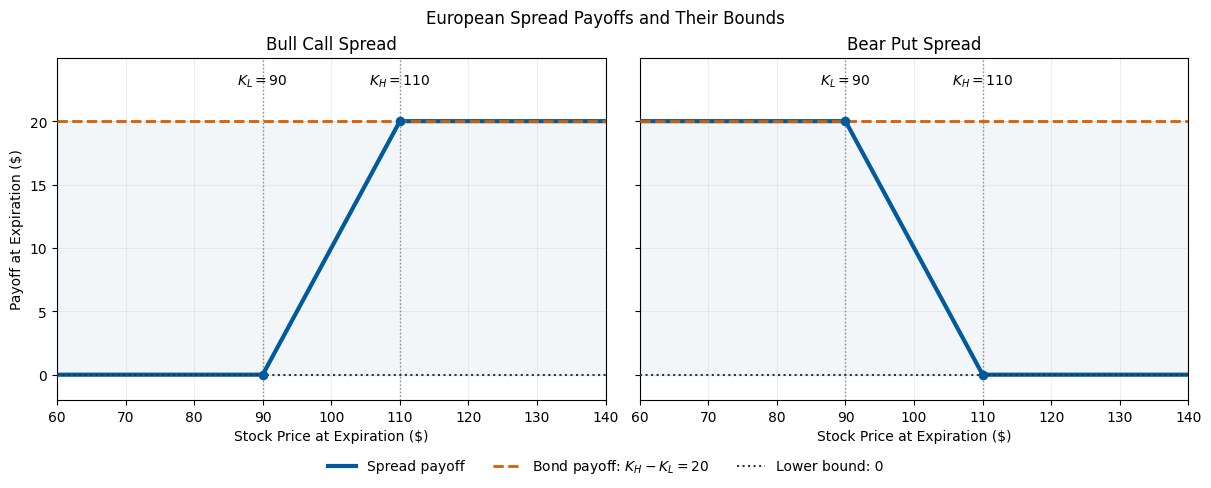

At expiration: each spread pays between USD 0 and USD 20.
Today, with 1 year to expiration and a 4% continuously compounded rate:
0 <= spread price <= 20 exp(-0.04) = USD 19.22.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Same strikes as the earlier spread examples; payoffs are per share.
lower_strike, upper_strike = 90, 110
spread_width = upper_strike - lower_strike
terminal_stock = np.linspace(60, 140, 401)

bull_call_payoff = (np.maximum(terminal_stock-lower_strike, 0)
                   - np.maximum(terminal_stock-upper_strike, 0))
bear_put_payoff = (np.maximum(upper_strike-terminal_stock, 0)
                  - np.maximum(lower_strike-terminal_stock, 0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True,
                         layout="constrained")
for ax, title, payoff in zip(
        axes, ["Bull Call Spread", "Bear Put Spread"],
        [bull_call_payoff, bear_put_payoff]):
    ax.fill_between(terminal_stock, 0, spread_width, color="#005A9C", alpha=0.05)
    ax.plot(terminal_stock, payoff, color="#005A9C", lw=3,
            label="Spread payoff", zorder=3)
    ax.axhline(spread_width, color="#D55E00", ls="--", lw=2,
               label=r"Bond payoff: $K_H-K_L=20$", zorder=4)
    ax.axhline(0, color="#333333", ls=":", lw=1.5,
               label="Lower bound: 0", zorder=4)
    for strike, label in [(lower_strike, r"$K_L=90$"),
                          (upper_strike, r"$K_H=110$")]:
        ax.axvline(strike, color="#888888", ls=":", lw=1)
        ax.text(strike, 23.2, label, ha="center", va="center")
    ax.scatter([lower_strike, upper_strike],
               np.interp([lower_strike, upper_strike], terminal_stock, payoff),
               color="#005A9C", s=35, zorder=5)
    ax.set(title=title, xlabel="Stock Price at Expiration ($)",
           xlim=(60, 140), ylim=(-2, 25), yticks=[0, 5, 10, 15, 20])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Payoff at Expiration ($)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("European Spread Payoffs and Their Bounds")
plt.show()

spread_rate, spread_years = 0.04, 1
pv_spread_width = spread_width*np.exp(-spread_rate*spread_years)
print("At expiration: each spread pays between USD 0 and USD 20.")
print("Today, with 1 year to expiration and a 4% continuously compounded rate:")
print(f"0 <= spread price <= 20 exp(-0.04) = USD {pv_spread_width:.2f}.")


### Box Spreads and Butterfly Bounds

Consider European options with the same expiration and strikes $K_L<K_H$.

*   Box Spread
    *   Combining a bull call spread with a bear put spread gives a terminal payoff of $K_H-K_L$ in every state.

$$[C(K_L)-C(K_H)]+[P(K_H)-P(K_L)]
=PV(K_H-K_L)$$

*   With strikes of $90$ and $110$, $T=1$ and a continuously compounded rate of $4\%$:
    *   The box price is $20e^{-0.04}=\$19.22$.

*   Symmetric Butterfly
    *   Set $K_M=(K_L+K_H)/2$. The payoff lies between zero and $K_M-K_L$.

$$0\le C(K_L)-2C(K_M)+C(K_H)\le PV(K_M-K_L)$$

*   With strikes of $90$, $100$ and $110$, the butterfly price cannot exceed $10e^{-0.04}=\$9.61$.

---

